# 01 · PTF exploratory analysis

**Goal:** understand what drives the day-ahead electricity price (PTF) in Turkey and turn it into decisions for the forecasting model.

**Data:** `data/processed/ptf_hourly.parquet`, built by `python -m scripts.build_dataset` from EPİAŞ Transparency Platform tables (hourly, Turkish time).

**Forecast-time rule:** tomorrow's prices are set in the day-ahead market; offers close at 12:30 and prices are announced at 14:00. A forecast must only use what is known before 12:30. Realized generation and consumption appear here **only to describe** the market; model inputs are limited to columns labelled `known_ahead` (or lagged `past_only` columns) in `src/dataset.py`.

Every finding is written as *number → meaning → consequence for the model*. Relationships shown here are associations, not causal claims.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # notebooks run from notebooks/; make `src` importable

import pandas as pd
from src.config import PROCESSED_DIR
from src import plots

pd.set_option('display.width', 160)
table = pd.read_parquet(PROCESSED_DIR / 'ptf_hourly.parquet')
print(f'{len(table):,} hours, {table.index.min():%Y-%m-%d} -> {table.index.max():%Y-%m-%d}')

33,552 hours, 2023-01-01 -> 2026-10-29


## 2.1 How did the price change over time, and why do TRY and USD differ?

Daily mean PTF in TRY (with the price cap in force) and in USD, on the same time axis.

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/01_daily_price_try_usd.png')

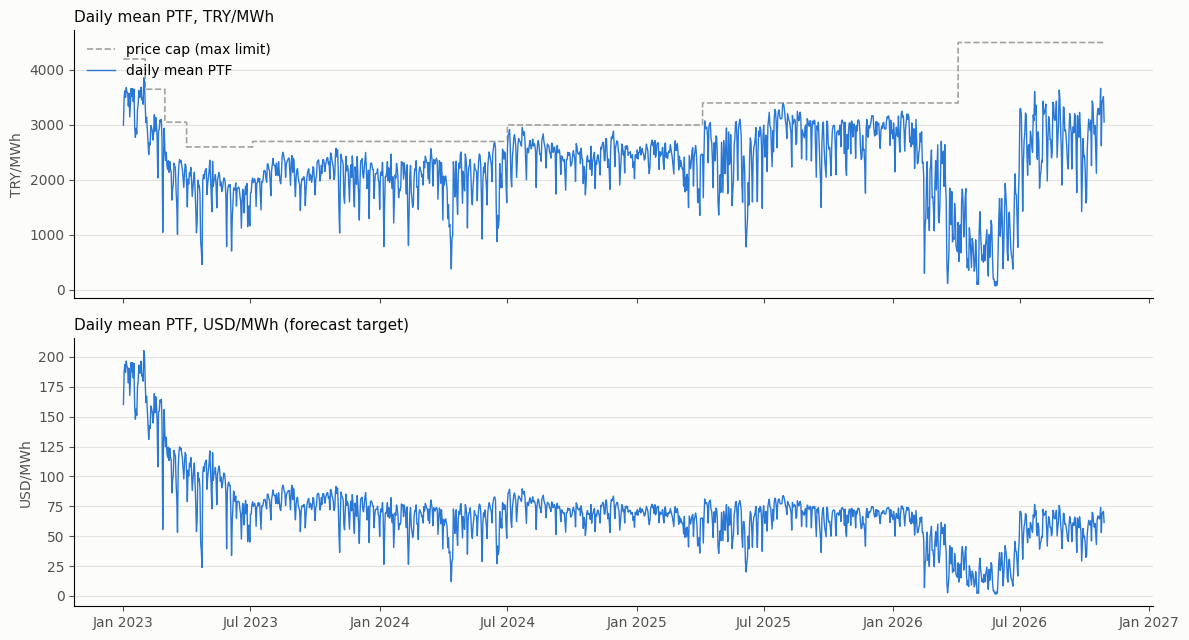

In [2]:
fig = plots.daily_price_try_usd(table)
plots.save(fig, '01_daily_price_try_usd')

In [3]:
plots.yearly_summary(table)

,hours,mean_ptf_try,mean_ptf_usd,floor_hours,cap_hours,implied_try_per_usd
timestamp,,,,,,
2023,8760,2189.30,96.56,10,1013,25.82
2024,8784,2235.52,68.10,4,1102,32.78
2025,8760,2619.81,66.42,42,1210,39.72
2026,7248,2057.25,44.58,413,407,45.90


**Findings (2.1)**

1. **TRY prices are flat, USD prices fall.** Mean PTF rose from 2,189 TRY/MWh (2023) to 2,620 (2025), while in USD it fell from 96.6 to 66.4. The gap is the exchange rate: the TRY/USD ratio implied by EPİAŞ's own two price columns rises every year (median 25.8 → 32.8 → 39.7 → 45.9). → TRY prices are not comparable across years; the **USD target** is the stable one (roughly 60–80 USD/MWh from mid-2023 to end-2025).
2. **Early 2023 is a different regime.** January–March 2023 daily means are 150–200 USD/MWh, falling to about 75 by mid-2023, while the price cap was cut from 4,200 to 2,600 TRY/MWh. → Whether to include this period in training is a model decision (Phase 3).
3. **A deep drop in spring 2026.** In April–June 2026 the daily mean falls to 0–25 USD/MWh and recovers to 60–70 from July; 413 of the 469 floor hours are in 2026. → The model must be able to explain this through renewables and demand inputs (examined in 2.5).

_Note: the source and timing of the exchange rate behind EPİAŞ's USD column are not documented; the implied rate is shown only as a ratio of the two price columns._

## 2.2 How are prices distributed, and how often do they hit the floor or the cap?

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/02_price_histogram_usd.png')

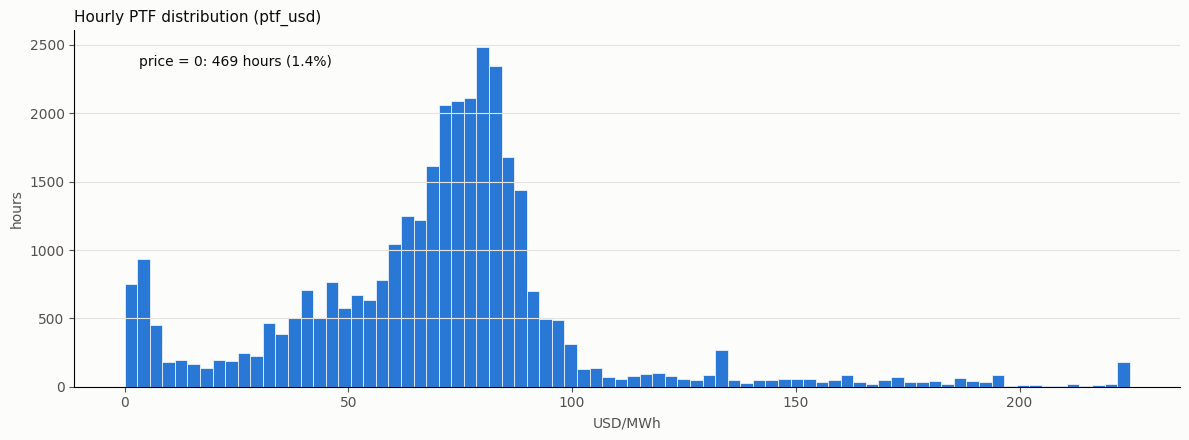

In [4]:
fig = plots.price_histogram(table, 'ptf_usd')
plots.save(fig, '02_price_histogram_usd')

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/03_floor_hours_month_hour.png')

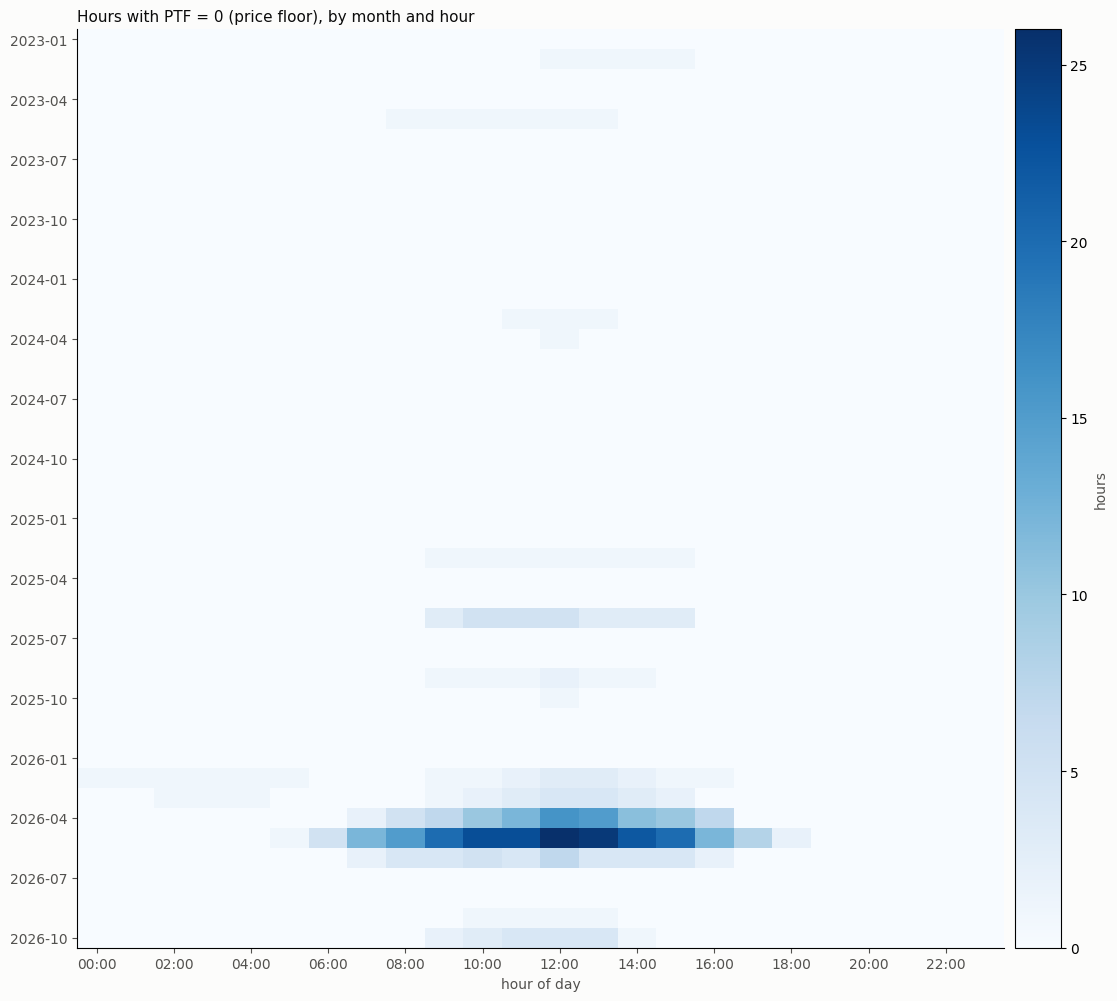

In [5]:
fig, floor_matrix = plots.month_hour_heatmap(
    table['is_price_floor'].astype(int), 'Hours with PTF = 0 (price floor), by month and hour', 'hours')
plots.save(fig, '03_floor_hours_month_hour')

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/04_cap_hours_month_hour.png')

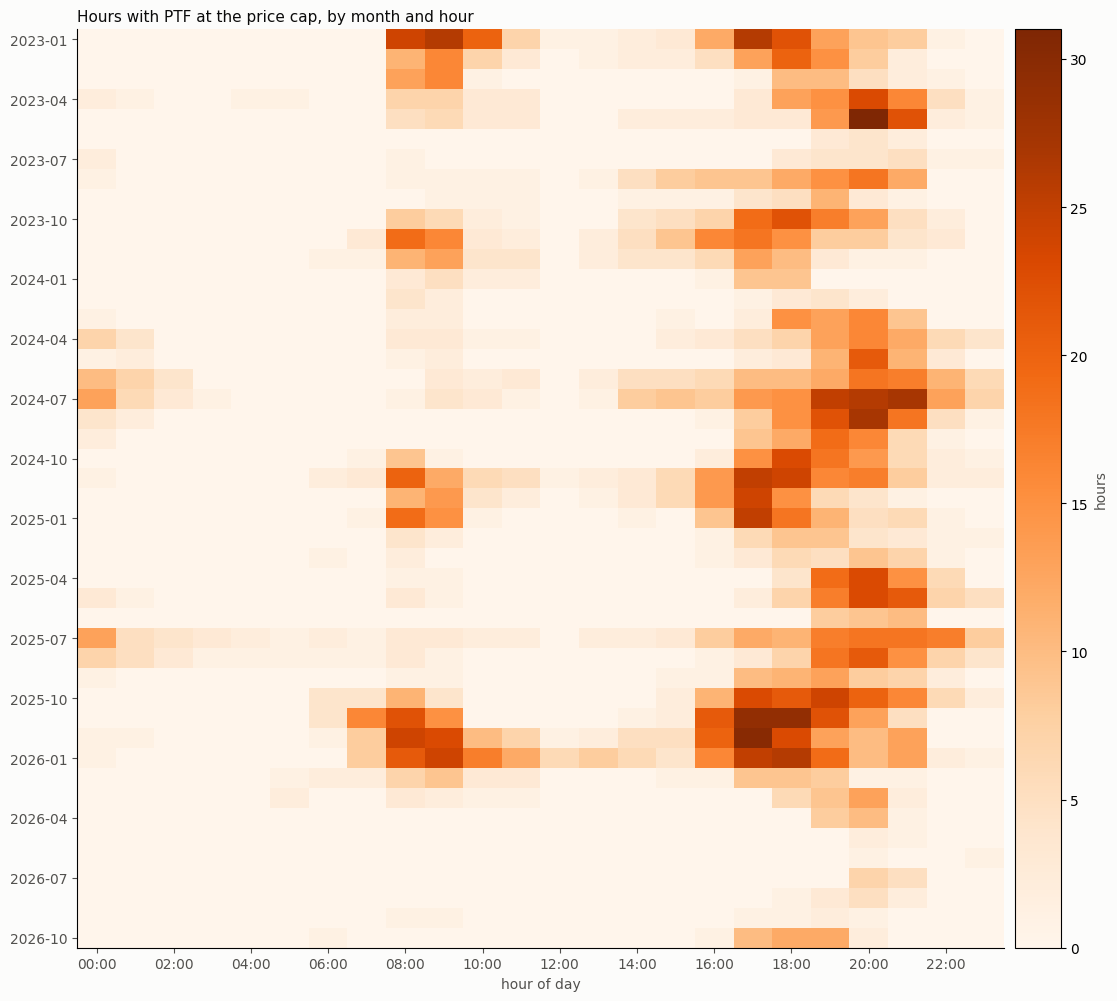

In [6]:
fig, cap_matrix = plots.month_hour_heatmap(
    table['is_price_cap'].astype(int), 'Hours with PTF at the price cap, by month and hour', 'hours',
    cmap='Oranges')
plots.save(fig, '04_cap_hours_month_hour')

**Findings (2.2)**

1. **Three clusters:** a main mass at 70–85 USD/MWh, a second cluster at 0–10 USD/MWh (floor and near-floor hours) and a long right tail up to about 225. → The distribution is not unimodal; errors should also be measured separately on floor and cap hours.
2. **Narrow spikes on the right are likely the price cap in USD.** The cap is fixed in TRY, so its USD value moves with the exchange rate and each cap period piles up at a different USD level (e.g. around 133 and 224). _This is an interpretation, not yet checked._ → In a USD target the cap is not a constant; the `price_cap_try` input may need converting to USD (Phase 3).
3. **Floor hours (PTF = 0)** fall almost entirely between 08:00 and 17:00 and peak in April–May 2026 (in May 2026 the price is 0 at 12:00 on 25 days). A few floor hours also occur at night (00:00–05:00) in February 2026, which solar cannot explain; the cause is unknown. → Hour of day and season are the strongest signals for the floor.
4. **Cap hours** show two peaks, 08:00–10:00 and 17:00–21:00, the evening one dominant; in winter both appear, in summer the peak shifts to 19:00–22:00 and in some years around midnight. After the cap was raised to 4,500 TRY/MWh on 4 April 2026, cap hours become rare. → The evening peak (T2, 17:00–22:00) carries the highest cap risk; the intraday profile (2.3) is central.

## 2.3 How does the price change within the day?

Mean PTF (USD) by month and hour, by tariff period (T1 06–17, T2 17–22, T3 22–06) and for weekdays vs weekends.

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/05_mean_price_month_hour.png')

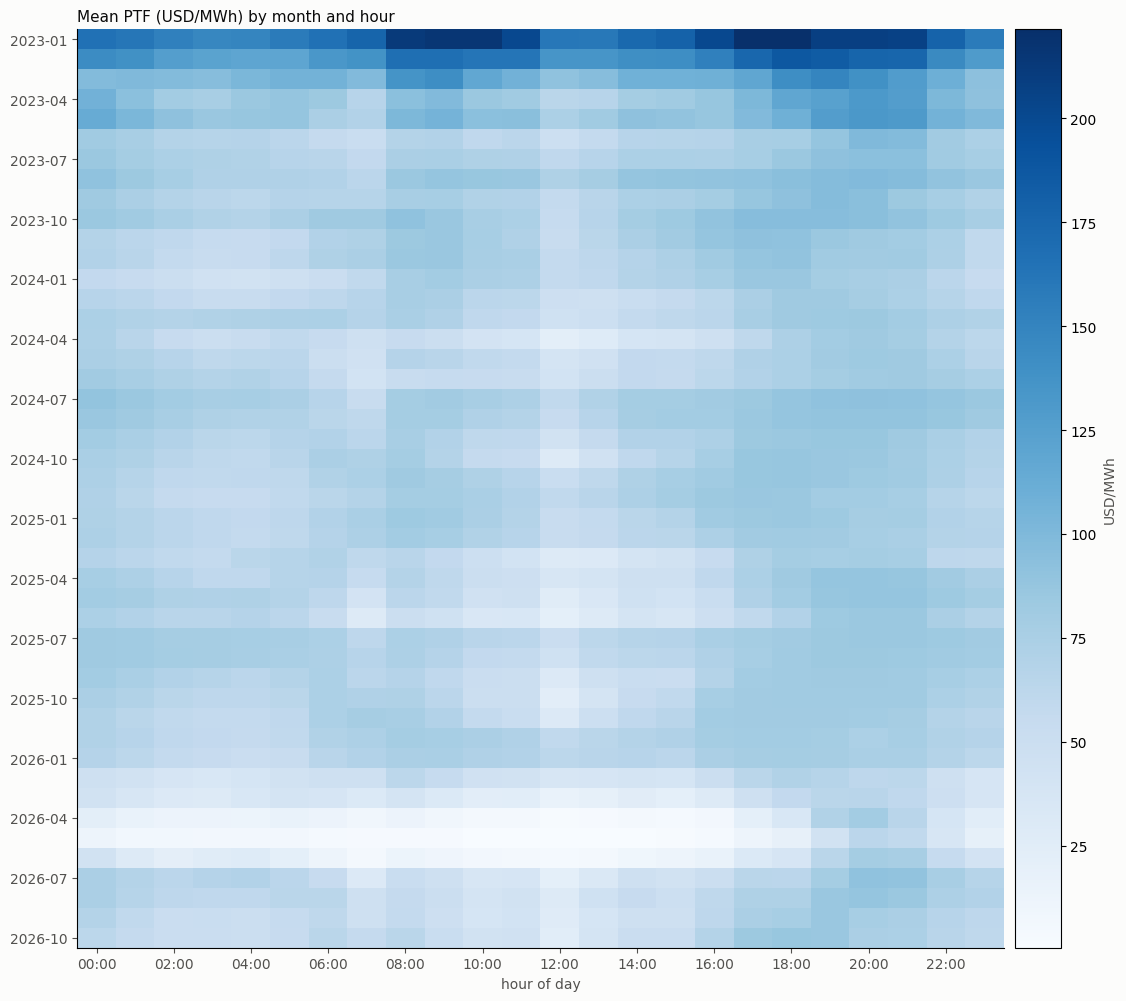

In [7]:
fig, price_matrix = plots.month_hour_heatmap(
    table['ptf_usd'], 'Mean PTF (USD/MWh) by month and hour', 'USD/MWh', agg='mean')
plots.save(fig, '05_mean_price_month_hour')

In [8]:
plots.tariff_period_summary(table)

,T1 day,T2 peak,T3 night
timestamp,,,
2023,93.2,115.7,89.2
2024,62.7,81.7,67.1
2025,58.3,80.3,68.9
2026,34.3,66.6,45.0


timestamp,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,75.9,70.7,64.7,62.1,62.5,64.4,65.7,63.7,82.2,80.0,...,69.8,71.3,77.7,85.0,87.5,90.7,91.1,88.9,78.7,71.7
weekend,76.1,70.9,65.2,63.4,64.0,65.5,67.1,54.5,55.2,51.4,...,44.1,44.7,55.3,70.5,81.0,87.4,88.4,86.1,72.4,65.2


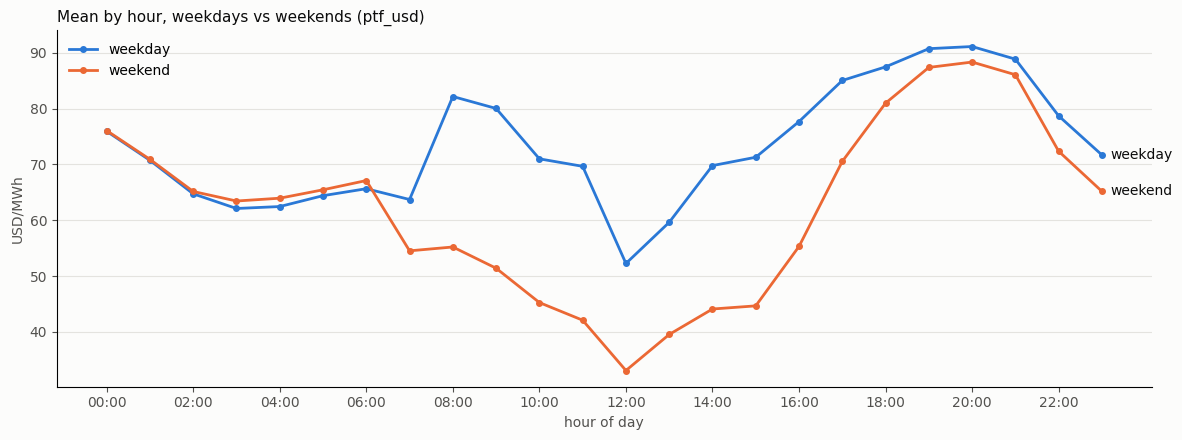

In [9]:
fig, profile = plots.weekday_weekend_profile(table)
plots.save(fig, '06_weekday_weekend_profile')
profile.T

**Findings (2.3)**

Tariff periods follow EPDK Board decision no. 6561 (27.10.2016): T1 06–17, T2 17–22, T3 22–06.

1. **The peak period (T2) is the most expensive every year** — in 2025 it is 38% above the day period (80.3 vs 58.3 USD/MWh), in 2026 almost twice (66.6 vs 34.3); evening columns (17:00–21:00) are the darkest in most months. → The peak carries the highest price (and, from 2.2, cap) risk.
2. **Since 2024 the day is cheaper than the night.** In 2023 T1 (93.2) was above T3 (89.2); from 2024 it is reversed (2025: 58.3 vs 68.9). This is consistent with growing solar output (checked in 2.5). → The hour-price relationship changes over the years; the model needs hour together with season and renewables, not a fixed daily profile.
3. **A distinct dip at 12:00.** In many months the 12:00 column is lighter than both 11:00 and 13:00; on weekdays the mean falls from 69.7 (11:00) to 52.3 (12:00) and rises to 59.7 (13:00). The cause is not established (a lunch-break drop in demand is one possibility, checked in 2.4).
4. **In spring 2026 the whole day is cheap, not only midday.** From March to June 2026 almost all hours, nights included, are very low, while 19:00–21:00 stays relatively higher. This cannot be explained by solar alone (examined in 2.5–2.6).
5. **Weekdays and weekends differ only in daytime.** Night hours are almost identical (03:00: 62.1 vs 63.4), daytime is 20–27 USD/MWh cheaper at weekends (08:00: 82.2 vs 55.2; 15:00: 71.3 vs 44.7), and the evening peak converges again (20:00: 91.1 vs 88.4). The weekday morning peak at 08:00–09:00 is absent at weekends. → Hour and day type act together (an interaction); tree-based models capture this directly, linear models would need it as an explicit feature.

## 2.4 How is the price related to demand?

Model input: EPİAŞ's load forecast for the next day (`load_forecast`, known ahead). Realized consumption is shown only to describe demand.

,x_mid,y_median,y_q25,y_q75,hours
bin,,,,,
"(17783.999, 30469.0]",29024.5,61.7,40.0,77.5,3360
"(30469.0, 32701.0]",31626.5,64.9,45.1,76.8,3352
"(32701.0, 34915.3]",33784.0,65.1,45.1,75.8,3354
"(34915.3, 37102.4]",36035.0,70.5,53.3,80.6,3355
"(37102.4, 38967.5]",38080.0,74.3,58.9,84.6,3355
"(38967.5, 40652.0]",39816.0,77.1,61.6,87.4,3356
"(40652.0, 42379.0]",41514.5,76.8,61.1,85.1,3356
"(42379.0, 44549.0]",43355.0,77.9,61.6,85.4,3355
"(44549.0, 47654.0]",45984.0,77.8,63.2,84.0,3355


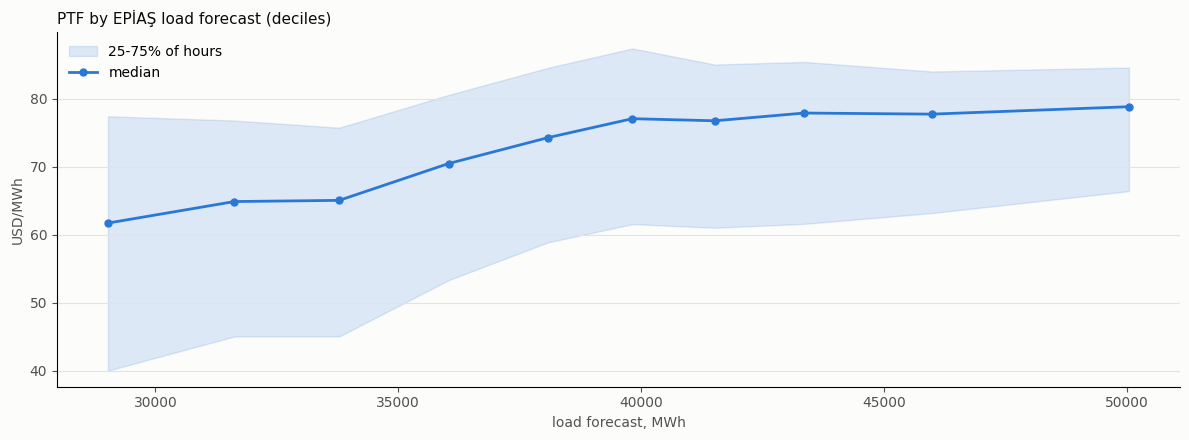

In [10]:
fig, load_bins = plots.price_by_bins(
    table, 'load_forecast', title='PTF by EPİAŞ load forecast (deciles)', xlabel='load forecast, MWh')
plots.save(fig, '07_price_by_load_forecast')
load_bins

timestamp,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,36864.7,35055.0,33734.8,32924.1,32607.5,32514.1,32837.6,34966.7,40361.5,43166.5,...,44997.5,44771.0,44917.7,44977.3,44331.6,44072.0,44032.2,43023.8,41511.0,39626.9
weekend,36533.8,34747.8,33290.4,32351.6,31899.0,31532.2,31094.9,31356.2,33584.9,35799.2,...,38892.8,38560.0,38533.4,39196.3,40099.2,40457.3,40625.7,39781.8,38506.7,36850.5


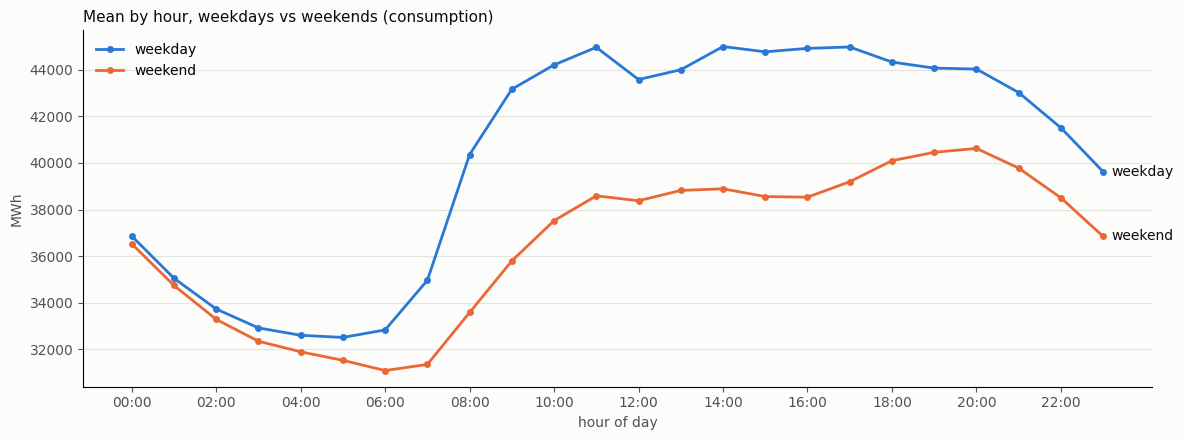

In [11]:
fig, consumption_profile = plots.weekday_weekend_profile(table, 'consumption', ylabel='MWh')
plots.save(fig, '08_consumption_weekday_weekend')
consumption_profile.T

**Findings (2.4)**

1. **Higher demand goes with higher prices, but the curve flattens.** Median PTF rises from 61.7 USD/MWh in the lowest load-forecast decile (~29,000 MWh) to about 77 around 40,000 MWh and stays near 78–79 above that. Spearman correlation is only 0.22 and the 25–75% bands are wide (roughly 40–80 at the same load). → Demand alone does not set the price; the load forecast stays an input but is not enough on its own.
2. **The 12:00 dip also appears in consumption.** Weekday consumption falls from about 45,000 MWh at 11:00 to about 43,600 at 12:00 (≈3%) and returns to about 44,000 at 13:00. This is consistent with the price dip in 2.3 (a lunch-break drop is plausible) but does not prove it, since solar output also peaks at that hour.
3. **Consumption and price have different daily shapes.** Weekday consumption is roughly flat between 10:00 and 17:00, while the price falls around midday and rises in the evening. → The daytime price seems driven more by the supply side (solar) than by demand, in line with 2.5.

## 2.5 How do wind and solar relate to the price?

Model inputs: the wind forecast (`wind_forecast`) and the load forecast, both known ahead. Their difference, *net load* = load forecast − wind forecast, is the demand left for other sources. No solar forecast is available, so solar appears only through realized generation (descriptive, never a same-hour input).

,x_mid,y_median,y_q25,y_q75,hours
bin,,,,,
"(2.629, 1053.808]",754.077,77.2,64.9,85.0,3356
"(1053.808, 1573.703]",1330.617,77.4,64.2,87.1,3355
"(1573.703, 2059.211]",1810.592,76.1,62.9,85.4,3355
"(2059.211, 2643.733]",2348.230,74.5,60.0,85.3,3355
"(2643.733, 3258.78]",2935.510,74.3,58.8,84.3,3355
"(3258.78, 3973.696]",3598.255,72.3,54.3,82.6,3355
"(3973.696, 4771.264]",4357.675,71.2,51.2,82.2,3355
"(4771.264, 5686.149]",5217.758,70.1,47.8,81.7,3355
"(5686.149, 6861.219]",6247.903,67.8,45.0,79.3,3355


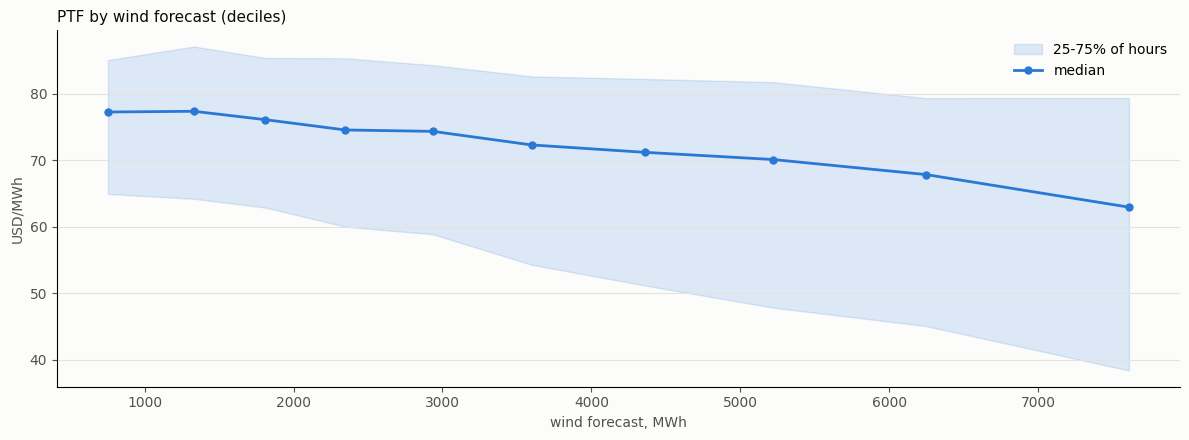

In [12]:
fig, wind_bins = plots.price_by_bins(
    table, 'wind_forecast', title='PTF by wind forecast (deciles)', xlabel='wind forecast, MWh')
plots.save(fig, '09_price_by_wind_forecast')
wind_bins

,x_mid,y_median,y_q25,y_q75,hours
bin,,,,,
"(15484.839, 27092.202]",25078.771,48.4,31.4,69.6,3356
"(27092.202, 29413.423]",28337.137,64.9,45.2,77.2,3355
"(29413.423, 31392.923]",30413.213,66.8,51.5,76.4,3355
"(31392.923, 33433.963]",32425.345,70.4,54.5,79.3,3355
"(33433.963, 35288.815]",34389.630,74.0,61.2,83.8,3355
"(35288.815, 37111.93]",36230.455,77.1,63.8,86.0,3355
"(37111.93, 38885.76]",37992.870,77.6,62.4,86.5,3355
"(38885.76, 40898.664]",39862.303,78.5,64.6,85.2,3355
"(40898.664, 43672.132]",42133.645,79.5,67.1,85.6,3355


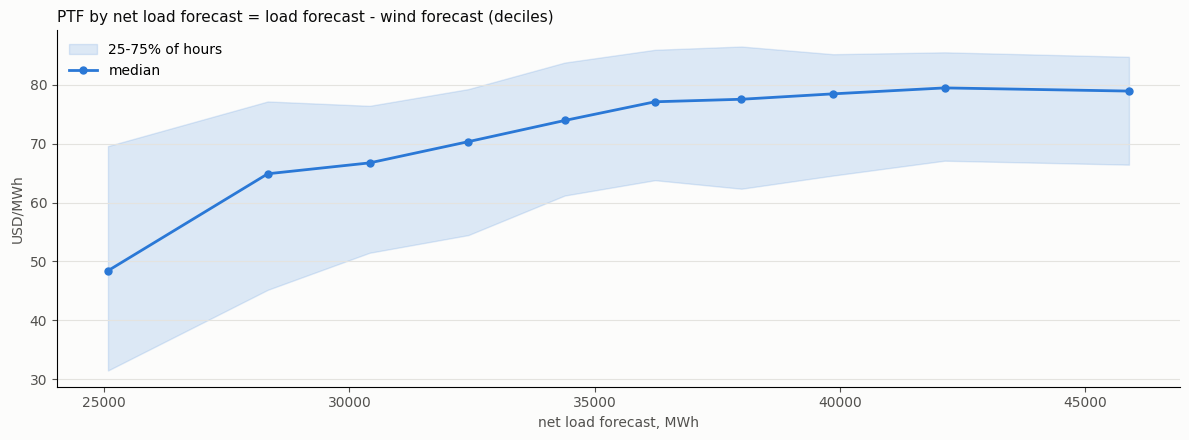

In [13]:
table['net_load_forecast'] = table['load_forecast'] - table['wind_forecast']
fig, net_load_bins = plots.price_by_bins(
    table, 'net_load_forecast', title='PTF by net load forecast = load forecast - wind forecast (deciles)',
    xlabel='net load forecast, MWh')
plots.save(fig, '10_price_by_net_load_forecast')
net_load_bins

,x_mid,y_median,y_q25,y_q75,hours
bin,,,,,
"(0.00233, 0.053]",0.039,82.2,73.7,89.3,3356
"(0.053, 0.0749]",0.064,81.0,72.2,89.5,3355
"(0.0749, 0.0947]",0.085,78.5,68.7,87.5,3355
"(0.0947, 0.114]",0.104,76.7,64.9,85.8,3355
"(0.114, 0.134]",0.124,74.5,61.4,83.9,3355
"(0.134, 0.154]",0.144,73.1,57.7,82.7,3355
"(0.154, 0.177]",0.165,71.3,55.0,81.2,3355
"(0.177, 0.204]",0.190,68.1,48.3,79.0,3355
"(0.204, 0.243]",0.222,58.1,39.6,73.9,3355


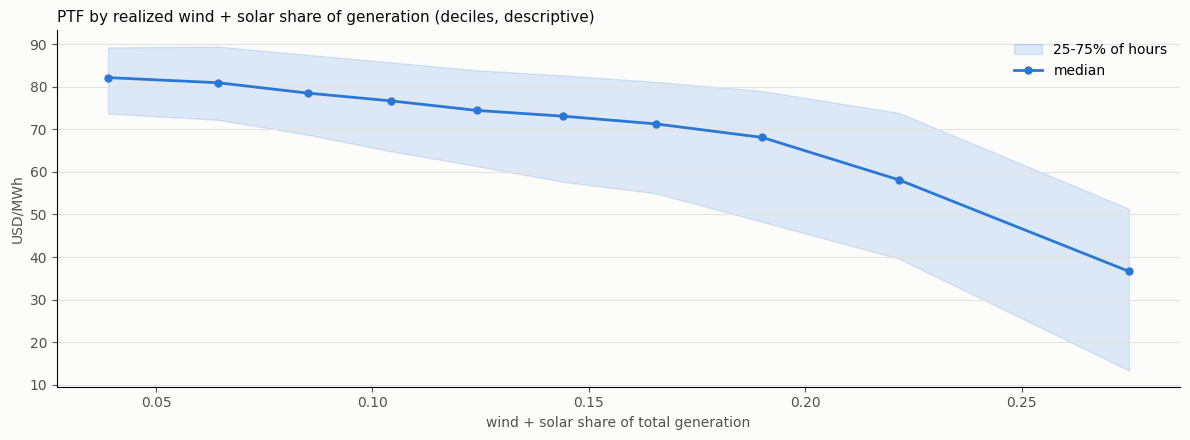

In [14]:
table['renewable_share'] = (table['gen_wind'] + table['gen_solar']) / table['gen_total']  # realized, descriptive
fig, share_bins = plots.price_by_bins(
    table, 'renewable_share', title='PTF by realized wind + solar share of generation (deciles, descriptive)',
    xlabel='wind + solar share of total generation')
plots.save(fig, '11_price_by_renewable_share')
share_bins

In [15]:
table[['ptf_usd', 'load_forecast', 'wind_forecast', 'net_load_forecast', 'renewable_share']].corr(method='spearman').round(2)

,ptf_usd,load_forecast,wind_forecast,net_load_forecast,renewable_share
ptf_usd,1.00,0.22,-0.19,0.29,-0.47
load_forecast,0.22,1.00,0.21,0.94,0.07
wind_forecast,-0.19,0.21,1.00,-0.11,0.81
net_load_forecast,0.29,0.94,-0.11,1.00,-0.19
renewable_share,-0.47,0.07,0.81,-0.19,1.00


**Findings (2.5)**

Spearman correlation with PTF: load forecast +0.22, wind forecast −0.19, **net load forecast +0.29**, realized wind + solar share −0.47 (descriptive only).

1. **More wind goes with lower prices.** Median PTF falls from 77.2 USD/MWh in the lowest wind-forecast decile to 62.9 in the highest — weak but steady.
2. **Net load (load forecast − wind forecast) is more informative than either part.** Its correlation (0.29) is higher than load (0.22) or wind (−0.19) alone; the median rises from 48.4 USD/MWh in the lowest decile (~25,000 MWh) and flattens around 77–79 above ~36,000. → Add net load as a feature in Phase 3; it is leakage-free because both parts are known ahead.
3. **The strongest relationship is with the renewable share — and the model lacks part of it.** With realized wind + solar below 5% of generation the median is 82.2 USD/MWh; above 24% it is 36.6. Wind has a forecast, **solar does not**, and solar likely explains much of this difference (2.3: daytime cheaper than night since 2024; 2.4: daytime price falls while demand is flat). → This may be the main missing input. Options for Phase 3: (a) lagged solar (e.g. same hour yesterday, leakage-free), (b) calendar features (hour × month) as a proxy for the solar cycle, (c) an external solar irradiance or weather forecast (not yet researched).

**Overall:** no single variable determines the price (all correlations below 0.5, wide bands). The price results from hour, day type, season, demand and supply (especially solar and wind) together — which supports comparing a model that captures interactions (XGBoost) with one that learns sequential patterns (LSTM).

## 2.6 Which sources generate in which hours?

Mean generation by hour and source group for January–October 2023 vs January–October 2026 (same months, so seasons are comparable), and the monthly share of the main sources. Realized generation, descriptive.

PosixPath('/home/kaanu/code/bitirme/turkey-electricity-forecasting/reports/figures/eda/12_generation_mix_by_hour_2023_vs_2026.png')

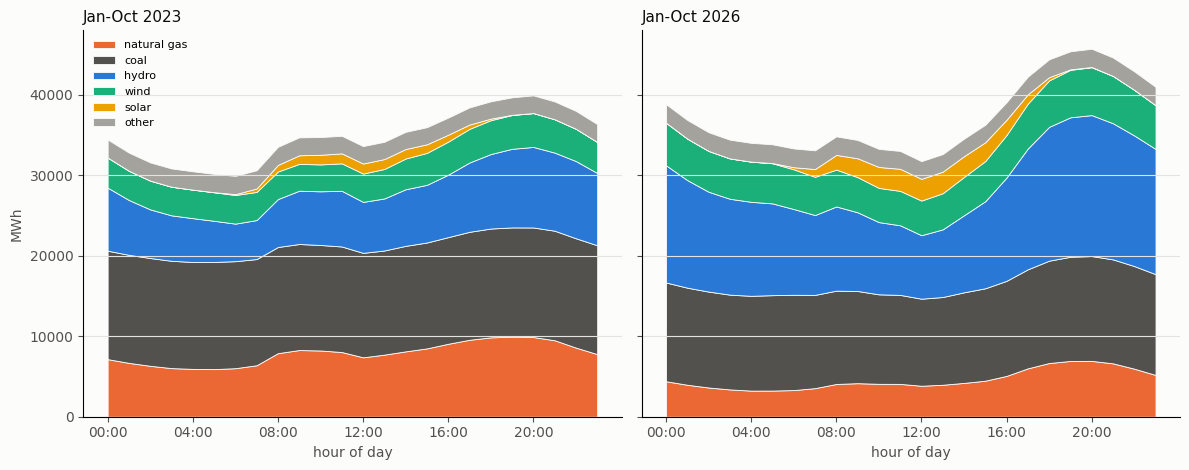

In [16]:
jan_oct = table.index.month <= 10
fig = plots.generation_mix_by_hour(table, {
    'Jan-Oct 2023': jan_oct & (table.index.year == 2023),
    'Jan-Oct 2026': jan_oct & (table.index.year == 2026)})
plots.save(fig, '12_generation_mix_by_hour_2023_vs_2026')

,solar,wind,hydro,natural gas
timestamp,,,,
2026-02-01 00:00:00+03:00,0.015,0.156,0.317,0.101
2026-03-01 00:00:00+03:00,0.023,0.137,0.397,0.076
2026-04-01 00:00:00+03:00,0.026,0.109,0.475,0.086
2026-05-01 00:00:00+03:00,0.027,0.101,0.499,0.115
2026-06-01 00:00:00+03:00,0.038,0.132,0.410,0.099
2026-07-01 00:00:00+03:00,0.039,0.136,0.300,0.115


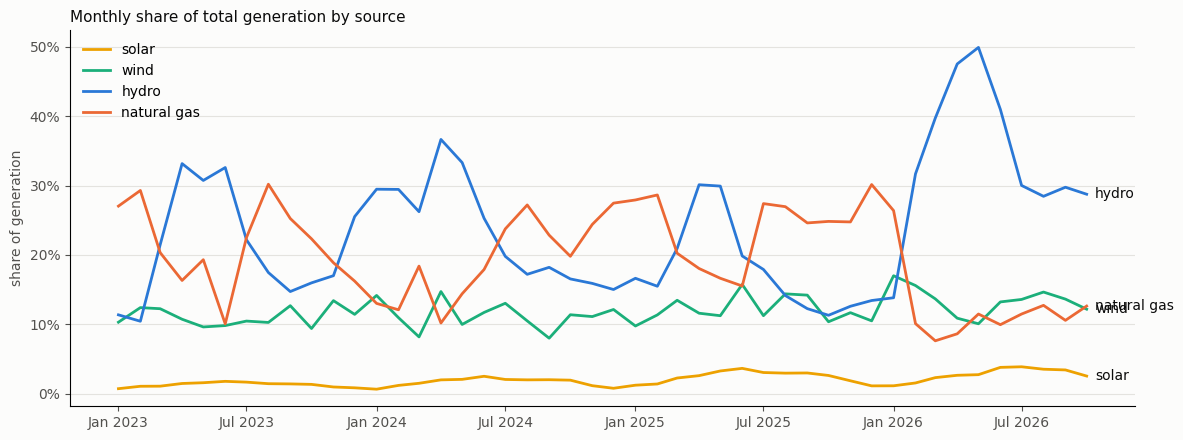

In [17]:
fig, source_share = plots.monthly_source_share(table)
plots.save(fig, '13_monthly_source_share')
source_share.loc['2026-02':'2026-07']

**Findings (2.6)**

1. **The supply side of cheap spring 2026: hydro.** Hydro reached 31.7% of generation in February 2026, 47.5% in April and **49.9% in May** — the highest share since 2023 (earlier peaks were 33–37%) — while natural gas fell to about 8–12% (often 15–30% in 2023–2025). → This matches 2.3, where in spring 2026 the whole day, nights included, was cheap: hydro also generates at night, solar does not. It is an association; the hydrological conditions of that year are not checked here. Hydro has no day-ahead forecast in our data, so it can only enter the model lagged (e.g. yesterday's hydro); reservoir data from EPİAŞ (noted earlier, not yet tested) is a candidate for Phase 3.
2. **Solar is much smaller in `rt-gen` than the price pattern suggests.** Solar is only 1–4% of generation throughout 2023–2026, a thin band at midday, yet 2.3 showed daytime prices falling and 2.5 found the renewable share to be the strongest correlate of price. _A possible explanation (not verified): `rt-gen` covers plants monitored in real time (likely licensed ones), while unlicensed, distributed solar may not appear in it, so actual solar output could be much larger than measured and act on prices indirectly._ → Open question for the instructor; the answer decides the solar input in Phase 3.
3. **Total generation and the evening peak are higher in 2026** (about 46,000 vs 40,000 MWh at the evening maximum), with hydro covering most of the evening increase.

## 2.7 How much does the price repeat itself?

Autocorrelation of hourly PTF (USD). At forecast time (before 12:30 on day D) today's 24 prices are known, so for a target hour h on day D+1 the most recent known price is at least h+1 hours old; the same hour yesterday (lag 24) and last week (lag 168) are always available.

1      0.929
24     0.830
48     0.774
168    0.822
dtype: float64

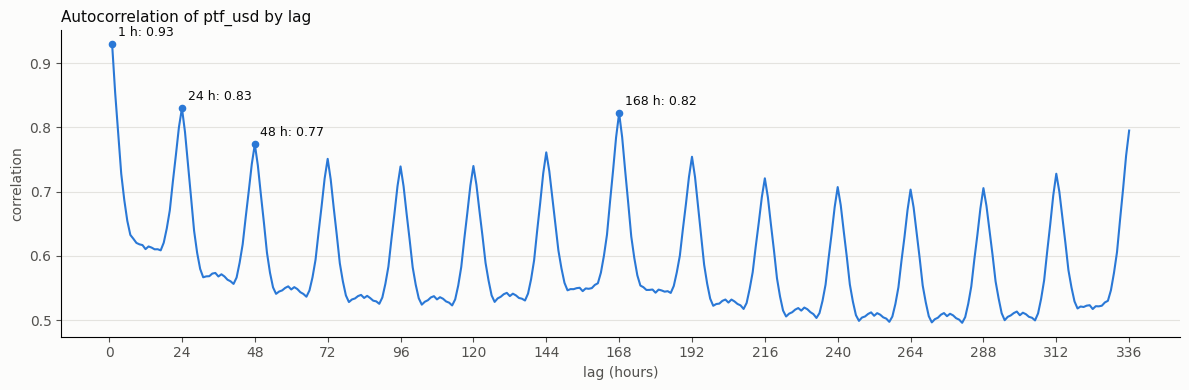

In [18]:
fig, acf_marks = plots.autocorrelation(table['ptf_usd'])
plots.save(fig, '14_price_autocorrelation')
acf_marks

**Findings (2.7)**

Autocorrelation of PTF (USD): 1 h 0.93, **24 h 0.83**, 48 h 0.77, **168 h 0.82**.

1. **A clear daily cycle:** peaks every 24 hours.
2. **The weekly link is as strong as the daily one** — lag 168 (0.82) is almost equal to lag 24 (0.83) and above lag 48 (0.77), consistent with the weekday/weekend difference in 2.3: the best reference for a Monday is the previous Monday, not Sunday.

→ Model inputs: **same hour yesterday (lag 24)** and **same hour last week (lag 168)**. Lag 1 is very strong but is not known at forecast time for most of tomorrow's hours; using it would be leakage.

## 2.8 How different are the balancing price (SMF) and the day-ahead price (PTF)?

Both in TRY/MWh (SMF is published only in TRY). SMF is known only after the hour, so it is used here for context and for the business layer (imbalance cost), not as a same-hour input.

,mean_spread_try,share_smf_above_ptf,share_smf_below_ptf,share_equal
timestamp,,,,
2023,-28.461,0.439,0.262,0.299
2024,-56.590,0.469,0.303,0.228
2025,-94.232,0.483,0.306,0.211
2026,11.937,0.411,0.398,0.191


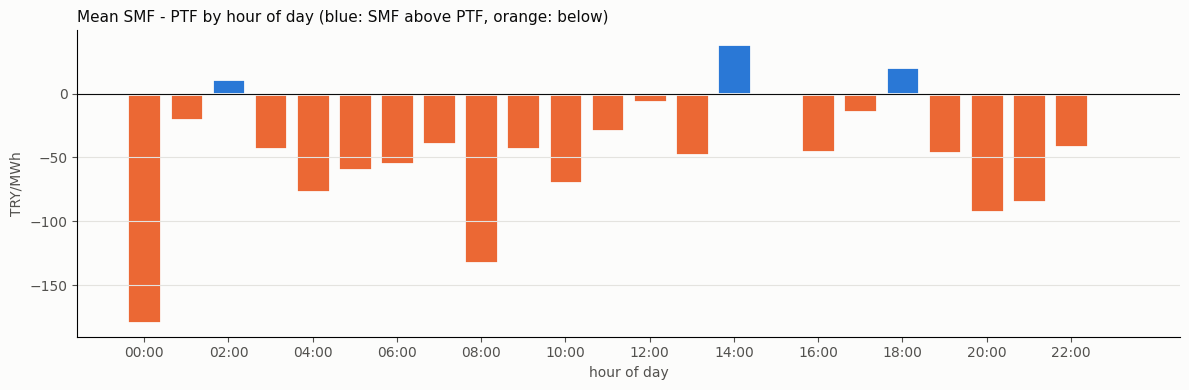

In [19]:
fig, spread = plots.smf_ptf_spread_by_hour(table)
plots.save(fig, '15_smf_ptf_spread_by_hour')
pd.DataFrame({
    'mean_spread_try': spread.groupby(spread.index.year).mean(),
    'share_smf_above_ptf': (spread > 0).groupby(spread.index.year).mean(),
    'share_smf_below_ptf': (spread < 0).groupby(spread.index.year).mean(),
    'share_equal': (spread == 0).groupby(spread.index.year).mean(),
}).round(3)

**Findings (2.8)**

| Year | Mean SMF − PTF (TRY) | SMF > PTF | SMF < PTF | Equal |
|---|---|---|---|---|
| 2023 | −28.5 | 43.9% | 26.2% | 29.9% |
| 2024 | −56.6 | 46.9% | 30.3% | 22.8% |
| 2025 | −94.2 | 48.3% | 30.6% | 21.1% |
| 2026 | +11.9 | 41.1% | 39.8% | 19.1% |

1. **Asymmetry:** SMF is above PTF in more hours, yet the mean difference is negative in most years — when SMF is below PTF, the gap is much larger.
2. **SMF equals PTF in 19–30% of hours;** the reason is not established.
3. **By hour,** the largest negative means are at 00:00 (about −180 TRY/MWh) and 08:00 (about −130).

→ The cost of an imbalance for a supplier can depend strongly on its direction (buying too much vs too little). This belongs to the business layer; the exact imbalance cost formula still has to be verified from the source before it is used.

## Summary: decisions for the model

| Decision | Evidence |
|---|---|
| Target: PTF in USD | 2.1 — TRY is not comparable across years |
| Inputs: hour, weekday/weekend, month — with interactions | 2.3 |
| Inputs: price at the same hour yesterday and last week | 2.7 |
| Inputs: load forecast, wind forecast, **net load forecast** | 2.4, 2.5 |
| Open: a solar input (does `rt-gen` include unlicensed solar?) | 2.5, 2.6 |
| Open: hydro generation / reservoir data | 2.6 |
| Open: include the high-price period of early 2023 in training? | 2.1 |
| Evaluation: also measure errors on floor and cap hours | 2.2 |

All relationships above are associations measured on 2023-01-01 → 2026-10-29 data; none is a causal claim.